In [9]:
import yfinance as yf

print(yf.__version__)

1.7.0


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

In [13]:
ticker = "TCS.NS"

tcs = yf.Ticker(ticker)

data = tcs.history(
    start="2007-01-01",
    end="2026-09-24",
    interval="1d"
)

print("Data downloaded successfully!")
print("Shape:", data.shape)

Data downloaded successfully!
Shape: (4866, 7)


In [14]:
data.reset_index(inplace=True)

print(data.head())

                       Date        Open        High         Low       Close  \
0 2007-01-02 00:00:00+05:30  199.632771  204.276900  197.456844  202.734268   
1 2007-01-03 00:00:00+05:30  203.464990  209.148369  201.215999  207.873672   
2 2007-01-04 00:00:00+05:30  208.661168  208.661168  202.994024  204.447357   
3 2007-01-05 00:00:00+05:30  205.413632  205.998204  203.481278  205.088867   
4 2007-01-08 00:00:00+05:30  204.439318  204.439318  197.294497  201.971115   

    Volume  Dividends  Stock Splits  
0  1545060        0.0           0.0  
1  4384972        0.0           0.0  
2  3970700        0.0           0.0  
3  2718740        0.0           0.0  
4  4951892        0.0           0.0  


In [15]:
data = data[
    ["Date", "Open", "High", "Low", "Close", "Volume"]
]

print(data.head())
print("\nColumns:")
print(data.columns)

                       Date        Open        High         Low       Close  \
0 2007-01-02 00:00:00+05:30  199.632771  204.276900  197.456844  202.734268   
1 2007-01-03 00:00:00+05:30  203.464990  209.148369  201.215999  207.873672   
2 2007-01-04 00:00:00+05:30  208.661168  208.661168  202.994024  204.447357   
3 2007-01-05 00:00:00+05:30  205.413632  205.998204  203.481278  205.088867   
4 2007-01-08 00:00:00+05:30  204.439318  204.439318  197.294497  201.971115   

    Volume  
0  1545060  
1  4384972  
2  3970700  
3  2718740  
4  4951892  

Columns:
Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='str')


In [16]:
print("Start Date:", data["Date"].min())
print("End Date:", data["Date"].max())
print("Total Records:", len(data))

Start Date: 2007-01-02 00:00:00+05:30
End Date: 2026-09-23 00:00:00+05:30
Total Records: 4866


In [17]:
print("Missing values:")
print(data.isnull().sum())

Missing values:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


In [18]:
print("Duplicate rows:", data.duplicated().sum())
print("Duplicate dates:", data["Date"].duplicated().sum())

Duplicate rows: 0
Duplicate dates: 0


In [19]:
data = data.drop_duplicates()
data = data.dropna()

data = data.sort_values("Date")
data = data.reset_index(drop=True)

print("Cleaned data shape:", data.shape)

Cleaned data shape: (4866, 6)


In [20]:
data["Target_Close"] = data["Close"].shift(-1)

print(data[[
    "Date",
    "Close",
    "Target_Close"
]].head())

                       Date       Close  Target_Close
0 2007-01-02 00:00:00+05:30  202.734268    207.873672
1 2007-01-03 00:00:00+05:30  207.873672    204.447357
2 2007-01-04 00:00:00+05:30  204.447357    205.088867
3 2007-01-05 00:00:00+05:30  205.088867    201.971115
4 2007-01-08 00:00:00+05:30  201.971115    204.017120


In [21]:
data = data.dropna().reset_index(drop=True)

print(data.tail())

                          Date         Open         High          Low  \
4860 2026-09-16 00:00:00+05:30  2257.996402  2261.875682  2160.514619   
4861 2026-09-17 00:00:00+05:30  2159.519904  2251.630339  2151.064852   
4862 2026-09-18 00:00:00+05:30  2165.687059  2165.786627  2090.088942   
4863 2026-09-21 00:00:00+05:30  2078.948294  2133.657459  2064.326074   
4864 2026-09-22 00:00:00+05:30  2123.809827  2123.909152  2087.104806   

            Close   Volume  Target_Close  
4860  2177.225830  2763709   2178.419434  
4861  2178.419434  3295917   2093.868896  
4862  2093.868896  6875428   2117.443604  
4863  2117.443604  2330811   2093.868896  
4864  2093.868896  3641623   2078.550293  


In [22]:
data.to_csv(
    "TCS_LinearRegression_Data_2007_2026.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


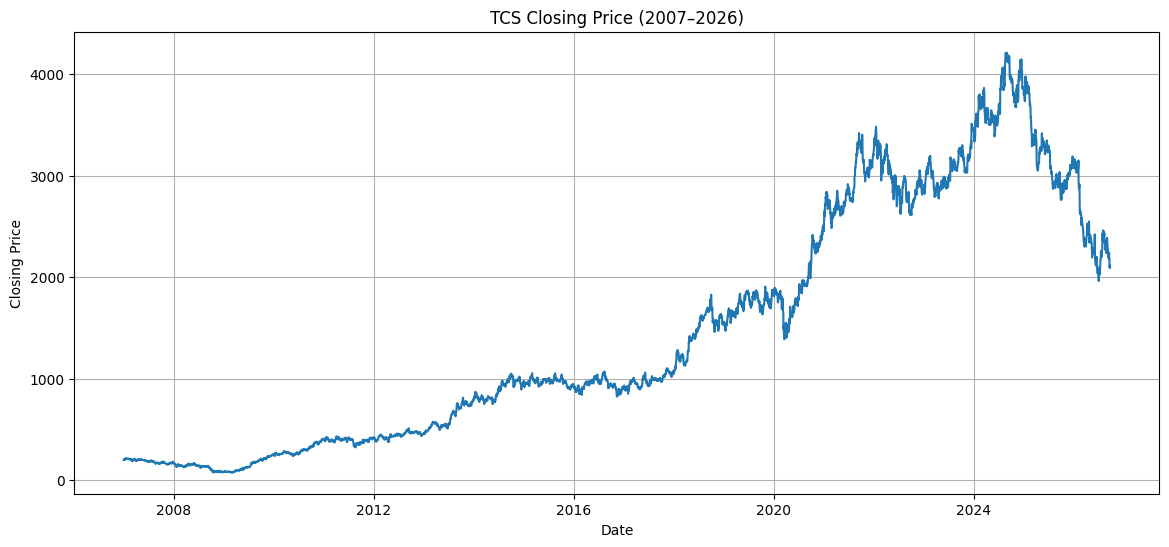

In [23]:
plt.figure(figsize=(14, 6))

plt.plot(
    data["Date"],
    data["Close"]
)

plt.title("TCS Closing Price (2007–2026)")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(True)

plt.show()

In [24]:
features = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume"
]

X = data[features]
y = data["Target_Close"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4865, 5)
y shape: (4865,)


In [25]:
split_index = int(len(data) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining period:")
print(data["Date"].iloc[0])
print("to")
print(data["Date"].iloc[split_index - 1])

print("\nTesting period:")
print(data["Date"].iloc[split_index])
print("to")
print(data["Date"].iloc[-1])

Training samples: 3892
Testing samples: 973

Training period:
2007-01-02 00:00:00+05:30
to
2022-10-13 00:00:00+05:30

Testing period:
2022-10-14 00:00:00+05:30
to
2026-09-22 00:00:00+05:30


In [26]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [27]:
y_pred = linear_model.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred[:10])

Predictions generated successfully!

First 10 predictions:
[2713.24252537 2732.39332622 2759.97579463 2740.38797287 2771.64943032
 2753.87080651 2775.42484121 2775.57623827 2771.31649631 2777.22555364]


In [28]:
mae = mean_absolute_error(
    y_test,
    y_pred
)

print("MAE:", mae)

MAE: 30.89191223899456


In [29]:
rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

print("RMSE:", rmse)

RMSE: 43.24297268555087


In [30]:
r2 = r2_score(
    y_test,
    y_pred
)

print("R²:", r2)

R²: 0.9928225081095536


In [26]:
import numpy as np

# Actual price movement
actual_direction = np.sign(
    y_test.values - X_test["Close"].values
)

# Predicted price movement
predicted_direction = np.sign(
    y_pred - X_test["Close"].values
)

# Directional Accuracy
directional_accuracy = (
    actual_direction == predicted_direction
).mean() * 100

print("Directional Accuracy:", directional_accuracy, "%")

Directional Accuracy: 47.43326488706365 %


In [27]:
print("X_train columns:")
print(X_train.columns.tolist())

print("\nX_test columns:")
print(X_test.columns.tolist())

print("\nTarget:")
print("y =", y.name)

X_train columns:
['Open', 'High', 'Low', 'Close', 'Volume']

X_test columns:
['Open', 'High', 'Low', 'Close', 'Volume']

Target:
y = Target_Close


In [28]:
print("Target column in X:",
      "Target_Close" in X.columns)

print("Target column in X_train:",
      "Target_Close" in X_train.columns)

print("Target column in X_test:",
      "Target_Close" in X_test.columns)

Target column in X: False
Target column in X_train: False
Target column in X_test: False


In [29]:
print("Current Close included:", "Close" in X.columns)
print("Number of features:", X.shape[1])

print("\nFirst 5 X rows:")
print(X.head())

print("\nFirst 5 y values:")
print(y.head())

Current Close included: True
Number of features: 5

First 5 X rows:
         Open        High         Low       Close   Volume
0  200.694102  205.362921  198.506607  203.812088  1545060
1  204.546655  210.260248  202.285708  208.978775  4384972
2  209.770500  209.770500  204.073227  205.534286  3970700
3  206.505629  207.093309  204.563003  206.179138  2718740
4  205.526108  205.526108  198.343306  203.044785  4951892

First 5 y values:
0    208.978775
1    205.534286
2    206.179138
3    203.044785
4    205.101685
Name: Target_Close, dtype: float64


In [30]:
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

print("\nTraining period:")
print(data.loc[X_train.index, "Date"].min())
print(data.loc[X_train.index, "Date"].max())

print("\nTesting period:")
print(data.loc[X_test.index, "Date"].min())
print(data.loc[X_test.index, "Date"].max())

X_train shape: (3895, 5)
X_test shape : (974, 5)

Training period:
2007-01-02 00:00:00+05:30
2022-10-18 00:00:00+05:30

Testing period:
2022-10-19 00:00:00+05:30
2026-09-22 00:00:00+05:30


In [31]:
print("\nLast 5 training rows:")
print(X_train.tail())

print("\nFirst 5 testing rows:")
print(X_test.head())


Last 5 training rows:
             Open         High          Low        Close   Volume
3890  2714.973908  2736.976031  2694.864096  2728.923340  1665247
3891  2728.922977  2737.063762  2686.326958  2731.167236  2054781
3892  2767.866374  2772.266797  2702.740106  2727.514404  2245977
3893  2711.191189  2760.382901  2710.132397  2745.691650  1517005
3894  2779.441945  2784.162671  2760.515312  2774.765381  1793722

First 5 testing rows:
             Open         High          Low        Close   Volume
3895  2787.383197  2787.383197  2745.912159  2754.603516  1194289
3896  2739.735697  2788.265637  2739.735697  2785.883301  1587601
3897  2786.324544  2788.618558  2759.147734  2768.324219  1021913
3898  2797.177600  2804.148178  2783.853839  2789.765625   260949
3899  2806.353791  2809.662650  2780.456367  2790.118408  2069643


In [35]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# -----------------------------
# Training Performance
# -----------------------------
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

# -----------------------------
# Testing Performance
# -----------------------------
test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

# -----------------------------
# Results
# -----------------------------
print("===== Linear Regression =====")

print("\nTraining Performance:")
print("MAE :", round(train_mae, 4))
print("RMSE:", round(train_rmse, 4))
print("R²  :", round(train_r2, 4))

print("\nTesting Performance:")
print("MAE :", round(test_mae, 4))
print("RMSE:", round(test_rmse, 4))
print("R²  :", round(test_r2, 4))

===== Linear Regression =====

Training Performance:
MAE : 12.0566
RMSE: 20.9318
R²  : 0.9994

Testing Performance:
MAE : 30.9676
RMSE: 43.4379
R²  : 0.9929


In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# -----------------------------------
# Naive Baseline Prediction
# -----------------------------------
# Predict tomorrow's Close as today's Close
naive_pred = X_test["Close"].values

# -----------------------------------
# Calculate Metrics
# -----------------------------------
naive_mae = mean_absolute_error(y_test, naive_pred)

naive_rmse = np.sqrt(
    mean_squared_error(y_test, naive_pred)
)

naive_r2 = r2_score(
    y_test,
    naive_pred
)

# -----------------------------------
# Display Results
# -----------------------------------
print("===== Naive Baseline =====")

print("MAE :", round(naive_mae, 4))
print("RMSE:", round(naive_rmse, 4))
print("R²  :", round(naive_r2, 4))

===== Naive Baseline =====
MAE : 30.8982
RMSE: 43.4146
R²  : 0.9929


In [37]:
import numpy as np

# Calculate percentage error for each prediction
percentage_error = (
    np.abs(y_test.values - y_test_pred)
    / np.abs(y_test.values)
) * 100

# Calculate prediction accuracy
prediction_accuracy = 100 - np.mean(percentage_error)

print("Prediction Accuracy:", round(prediction_accuracy, 2), "%")

Prediction Accuracy: 99.0 %


In [39]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# =========================================================
# 1. LINEAR REGRESSION PREDICTIONS
# =========================================================

# If your model is already trained:
y_lr_pred = model.predict(X_test)

# ---------------------------------------------------------
# Linear Regression metrics
# ---------------------------------------------------------

lr_mae = mean_absolute_error(y_test, y_lr_pred)

lr_rmse = np.sqrt(
    mean_squared_error(y_test, y_lr_pred)
)

lr_r2 = r2_score(
    y_test,
    y_lr_pred
)

# Prediction Accuracy
lr_percentage_error = (
    np.abs(y_test.values - y_lr_pred)
    / np.abs(y_test.values)
) * 100

lr_accuracy = 100 - np.mean(
    lr_percentage_error
)


# =========================================================
# 2. NAIVE BASELINE PREDICTIONS
# =========================================================

# Tomorrow's price = today's Close
y_naive_pred = X_test["Close"].values

# ---------------------------------------------------------
# Naive Baseline metrics
# ---------------------------------------------------------

naive_mae = mean_absolute_error(
    y_test,
    y_naive_pred
)

naive_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_naive_pred
    )
)

naive_r2 = r2_score(
    y_test,
    y_naive_pred
)

# Prediction Accuracy
naive_percentage_error = (
    np.abs(y_test.values - y_naive_pred)
    / np.abs(y_test.values)
) * 100

naive_accuracy = 100 - np.mean(
    naive_percentage_error
)


# =========================================================
# 3. CREATE COMPARISON TABLE
# =========================================================

comparison = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Linear Regression"
    ],

    "MAE": [
        naive_mae,
        lr_mae
    ],

    "RMSE": [
        naive_rmse,
        lr_rmse
    ],

    "R2": [
        naive_r2,
        lr_r2
    ],

    "Prediction Accuracy (%)": [
        naive_accuracy,
        lr_accuracy
    ]
})


# =========================================================
# 4. ROUND VALUES
# =========================================================

comparison["MAE"] = comparison["MAE"].round(4)
comparison["RMSE"] = comparison["RMSE"].round(4)
comparison["R2"] = comparison["R2"].round(4)
comparison["Prediction Accuracy (%)"] = (
    comparison["Prediction Accuracy (%)"].round(2)
)


# =========================================================
# 5. DISPLAY RESULTS
# =========================================================

print("===== MODEL COMPARISON =====\n")

print(comparison.to_string(index=False))

===== MODEL COMPARISON =====

            Model     MAE    RMSE     R2  Prediction Accuracy (%)
   Naive Baseline 30.8982 43.4146 0.9929                     99.0
Linear Regression 30.9676 43.4379 0.9929                     99.0


In [40]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# =========================================================
# 1. TRAINING AND TESTING PREDICTIONS
# =========================================================

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)


# =========================================================
# 2. CALCULATE TRAINING METRICS
# =========================================================

train_mae = mean_absolute_error(
    y_train,
    y_train_pred
)

train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        y_train_pred
    )
)

train_r2 = r2_score(
    y_train,
    y_train_pred
)


# =========================================================
# 3. CALCULATE TESTING METRICS
# =========================================================

test_mae = mean_absolute_error(
    y_test,
    y_test_pred
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred
    )
)

test_r2 = r2_score(
    y_test,
    y_test_pred
)


# =========================================================
# 4. CALCULATE TRAIN-TEST GAPS
# =========================================================

mae_gap = test_mae - train_mae
rmse_gap = test_rmse - train_rmse
r2_gap = train_r2 - test_r2


# =========================================================
# 5. DISPLAY METRICS
# =========================================================

print("=" * 55)
print("LINEAR REGRESSION - FITTING ANALYSIS")
print("=" * 55)

print("\nTraining Performance")
print("-" * 30)
print("MAE :", round(train_mae, 4))
print("RMSE:", round(train_rmse, 4))
print("R²  :", round(train_r2, 4))

print("\nTesting Performance")
print("-" * 30)
print("MAE :", round(test_mae, 4))
print("RMSE:", round(test_rmse, 4))
print("R²  :", round(test_r2, 4))

print("\nTrain-Test Gap")
print("-" * 30)
print("MAE Gap :", round(mae_gap, 4))
print("RMSE Gap:", round(rmse_gap, 4))
print("R² Gap  :", round(r2_gap, 4))


# =========================================================
# 6. AUTOMATIC FITTING CHECK
# =========================================================

# Relative error gaps
mae_gap_percent = (
    (test_mae - train_mae)
    / train_mae
) * 100

rmse_gap_percent = (
    (test_rmse - train_rmse)
    / train_rmse
) * 100


# ---------------------------------------------------------
# OVERFITTING CHECK
# ---------------------------------------------------------

if (
    r2_gap > 0.05
    and mae_gap_percent > 20
    and rmse_gap_percent > 20
):
    fitting_status = "OVERFITTING"

# ---------------------------------------------------------
# UNDERFITTING CHECK
# ---------------------------------------------------------

elif (
    train_r2 < 0.70
    and test_r2 < 0.70
):
    fitting_status = "UNDERFITTING"

# ---------------------------------------------------------
# REASONABLE GENERALIZATION
# ---------------------------------------------------------

else:
    fitting_status = "NO STRONG EVIDENCE OF OVERFITTING"


# =========================================================
# 7. FINAL RESULT
# =========================================================

print("\n" + "=" * 55)
print("FINAL FITTING ASSESSMENT")
print("=" * 55)

print("\nMAE Gap (%):", round(mae_gap_percent, 2), "%")
print("RMSE Gap (%):", round(rmse_gap_percent, 2), "%")

print("\nModel Status:", fitting_status)


# =========================================================
# 8. EXPLANATION
# =========================================================

if fitting_status == "OVERFITTING":

    print("""
Interpretation:
The model performs substantially better on the
training data than on unseen testing data.

This indicates that the model may be overfitting
the training data and may not generalize well.
""")

elif fitting_status == "UNDERFITTING":

    print("""
Interpretation:
The model performs poorly on both training and
testing data.

This indicates that the model may be too simple
to capture the underlying relationship.
""")

else:

    print("""
Interpretation:
The training and testing performance do not show
strong evidence of severe overfitting.

The model generalizes reasonably from the training
period to the testing period based on these metrics.

However, model performance should also be compared
against the naive baseline.
""")

LINEAR REGRESSION - FITTING ANALYSIS

Training Performance
------------------------------
MAE : 12.0566
RMSE: 20.9318
R²  : 0.9994

Testing Performance
------------------------------
MAE : 30.9676
RMSE: 43.4379
R²  : 0.9929

Train-Test Gap
------------------------------
MAE Gap : 18.911
RMSE Gap: 22.5061
R² Gap  : 0.0065

FINAL FITTING ASSESSMENT

MAE Gap (%): 156.85 %
RMSE Gap (%): 107.52 %

Model Status: NO STRONG EVIDENCE OF OVERFITTING

Interpretation:
The training and testing performance do not show
strong evidence of severe overfitting.

The model generalizes reasonably from the training
period to the testing period based on these metrics.

However, model performance should also be compared
against the naive baseline.



In [41]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# =========================================================
# 1. MODEL PREDICTIONS
# =========================================================

y_pred = model.predict(X_test)

# Actual today's closing price
current_close = X_test["Close"].values

# Actual next-day price
actual_price = y_test.values

# =========================================================
# 2. MAE
# =========================================================

mae = mean_absolute_error(
    actual_price,
    y_pred
)

# =========================================================
# 3. RMSE
# =========================================================

rmse = np.sqrt(
    mean_squared_error(
        actual_price,
        y_pred
    )
)

# =========================================================
# 4. R²
# =========================================================

r2 = r2_score(
    actual_price,
    y_pred
)

# =========================================================
# 5. DIRECTIONAL ACCURACY
# =========================================================

# Actual movement:
# Tomorrow's actual price - today's price
actual_direction = np.sign(
    actual_price - current_close
)

# Predicted movement:
# Tomorrow's predicted price - today's price
predicted_direction = np.sign(
    y_pred - current_close
)

directional_accuracy = (
    actual_direction == predicted_direction
).mean() * 100

# =========================================================
# 6. PREDICTION ACCURACY
# =========================================================

# Absolute percentage error
percentage_error = (
    np.abs(actual_price - y_pred)
    / np.abs(actual_price)
) * 100

# Accuracy based on price closeness
prediction_accuracy = (
    100 - np.mean(percentage_error)
)

# =========================================================
# 7. DISPLAY ALL METRICS
# =========================================================

print("=" * 55)
print("LINEAR REGRESSION - COMPLETE EVALUATION")
print("=" * 55)

print("\nMAE                  :", round(mae, 4))
print("RMSE                 :", round(rmse, 4))
print("R²                   :", round(r2, 4))
print("Directional Accuracy :", round(directional_accuracy, 2), "%")
print("Prediction Accuracy  :", round(prediction_accuracy, 2), "%")

LINEAR REGRESSION - COMPLETE EVALUATION

MAE                  : 30.9676
RMSE                 : 43.4379
R²                   : 0.9929
Directional Accuracy : 47.43 %
Prediction Accuracy  : 99.0 %


In [42]:
results = pd.DataFrame({
    "Model": ["Linear Regression"],
    "MAE": [mae],
    "RMSE": [rmse],
    "R²": [r2],
    "Directional Accuracy (%)": [directional_accuracy],
    "Prediction Accuracy (%)": [prediction_accuracy]
})

results = results.round({
    "MAE": 4,
    "RMSE": 4,
    "R²": 4,
    "Directional Accuracy (%)": 2,
    "Prediction Accuracy (%)": 2
})

print("\n===== MODEL EVALUATION TABLE =====")
display(results)


===== MODEL EVALUATION TABLE =====


,Model,MAE,RMSE,R²,Directional Accuracy (%),Prediction Accuracy (%)
0,Linear Regression,30.9676,43.4379,0.9929,47.43,99.0


In [45]:
comparison = pd.DataFrame({
    "Date": data["Date"].iloc[split_index:].values,
    "Actual_Close": y_test.values,
    "Predicted_Close": y_pred
})

comparison["Absolute_Error"] = (
    abs(
        comparison["Actual_Close"]
        - comparison["Predicted_Close"]
    )
)

comparison["Percentage_Error"] = (
    comparison["Absolute_Error"]
    / comparison["Actual_Close"]
) * 100

display(comparison.head(20))

,Date,Actual_Close,Predicted_Close,Absolute_Error,Percentage_Error
0,2022-10-18 18:30:00,2785.883301,2754.960825,30.922476,1.109970
1,2022-10-19 18:30:00,2768.324219,2786.420644,18.096425,0.653696
2,2022-10-20 18:30:00,2789.765625,2768.506174,21.259451,0.762052
3,2022-10-23 18:30:00,2790.118408,2790.172944,0.054535,0.001955
4,2022-10-24 18:30:00,2785.970703,2790.324304,4.353601,0.156269
5,2022-10-26 18:30:00,2791.133057,2786.048819,5.084238,0.182157
6,2022-10-27 18:30:00,2817.515381,2792.000924,25.514457,0.905566
7,2022-10-30 18:30:00,2876.237061,2817.089955,59.147105,2.056406
8,2022-10-31 18:30:00,2860.354736,2876.340332,15.985596,0.558868
9,2022-11-01 18:30:00,2829.516113,2860.175297,30.659184,1.083549


In [46]:
comparison.to_csv(
    "TCS_LinearRegression_Predictions_2007_2026.csv",
    index=False
)

print("Prediction comparison table saved!")

Prediction comparison table saved!


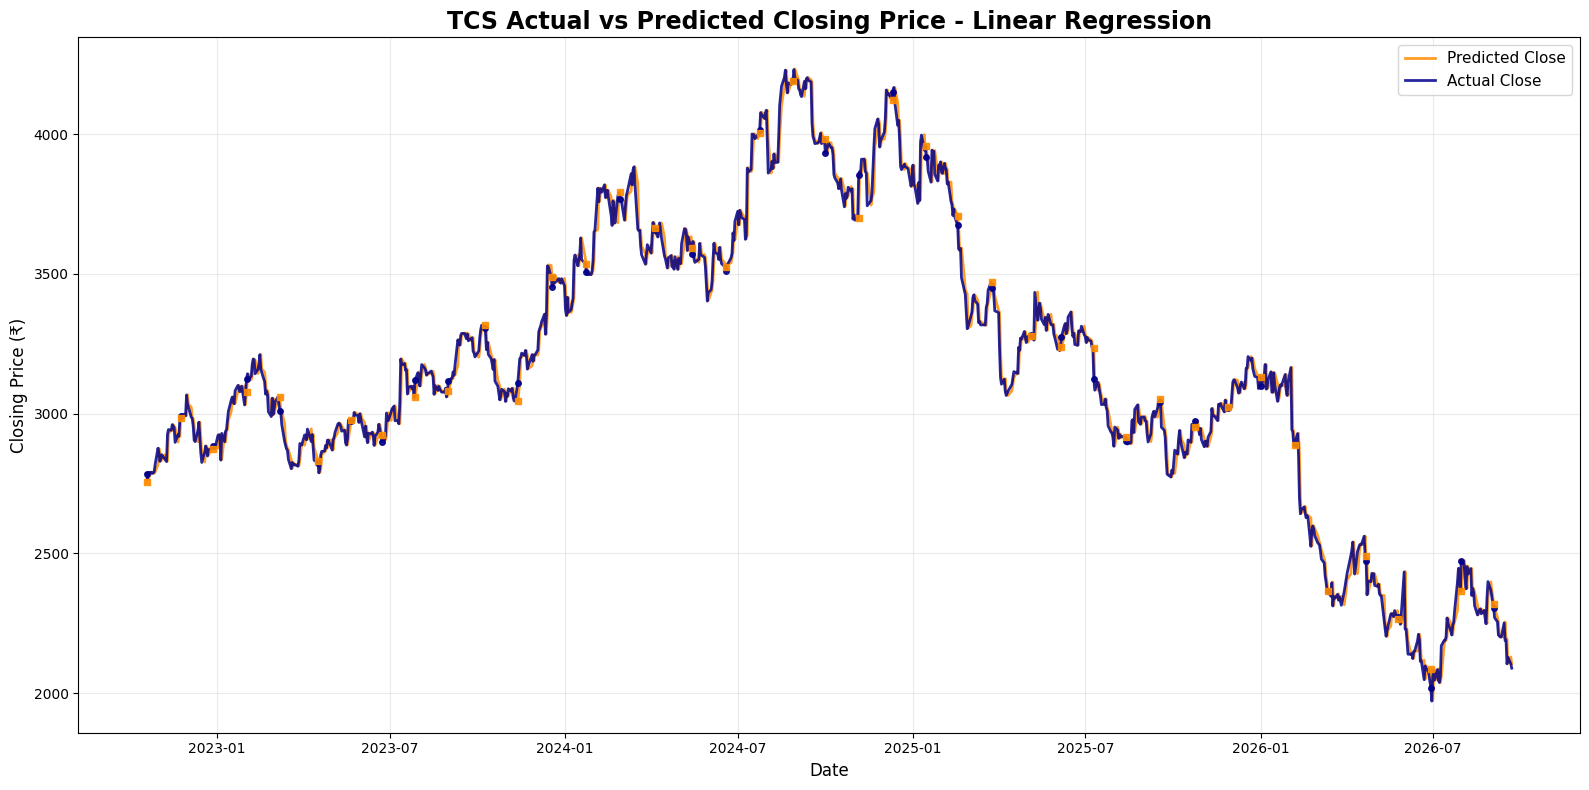

In [47]:
plt.figure(figsize=(16, 8))

# Predicted line first
plt.plot(
    comparison["Date"],
    comparison["Predicted_Close"],
    label="Predicted Close",
    color="darkorange",
    linewidth=2,
    alpha=0.85,
    zorder=2
)

# Actual line
plt.plot(
    comparison["Date"],
    comparison["Actual_Close"],
    label="Actual Close",
    color="darkblue",
    linewidth=2,
    alpha=0.85,
    zorder=3
)

# Add markers at intervals so both lines remain visually distinguishable
step = max(1, len(comparison) // 40)

plt.plot(
    comparison["Date"].iloc[::step],
    comparison["Actual_Close"].iloc[::step],
    linestyle="None",
    marker="o",
    markersize=4,
    color="darkblue",
    alpha=0.9,
    zorder=4
)

plt.plot(
    comparison["Date"].iloc[::step],
    comparison["Predicted_Close"].iloc[::step],
    linestyle="None",
    marker="s",
    markersize=4,
    color="darkorange",
    alpha=0.9,
    zorder=4
)

plt.title(
    "TCS Actual vs Predicted Closing Price - Linear Regression",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Date", fontsize=12)
plt.ylabel("Closing Price (₹)", fontsize=12)

plt.legend(
    fontsize=11,
    loc="upper right"
)

plt.grid(
    True,
    alpha=0.25
)

plt.tight_layout()
plt.show()

In [48]:
yearly_data = data.copy()

yearly_data["Year"] = (
    pd.to_datetime(yearly_data["Date"]).dt.year
)

yearly_summary = yearly_data.groupby("Year").agg(
    Average_Open=("Open", "mean"),
    Average_High=("High", "mean"),
    Average_Low=("Low", "mean"),
    Average_Close=("Close", "mean"),
    Total_Volume=("Volume", "sum")
).reset_index()

display(yearly_summary)

,Year,Average_Open,Average_High,Average_Low,Average_Close,Total_Volume
0,2007,189.840893,192.373374,186.173296,188.944282,1065861528
1,2008,132.039800,135.193580,127.777566,131.235880,1296917336
2,2009,150.462857,153.857945,147.739149,151.002784,1540637624
3,2010,300.354883,304.178266,296.358227,300.398559,840244724
4,2011,395.864267,401.196080,390.053404,395.530941,817976452
5,2012,446.518034,451.386043,441.414416,446.515168,667246580
6,2013,620.425791,628.680782,613.874815,621.355139,674954682
7,2014,891.007232,900.523897,880.653622,890.340184,578958206
8,2015,977.242909,985.519425,966.581050,975.524915,580144728
9,2016,945.904898,955.050691,935.410517,946.008146,539221804


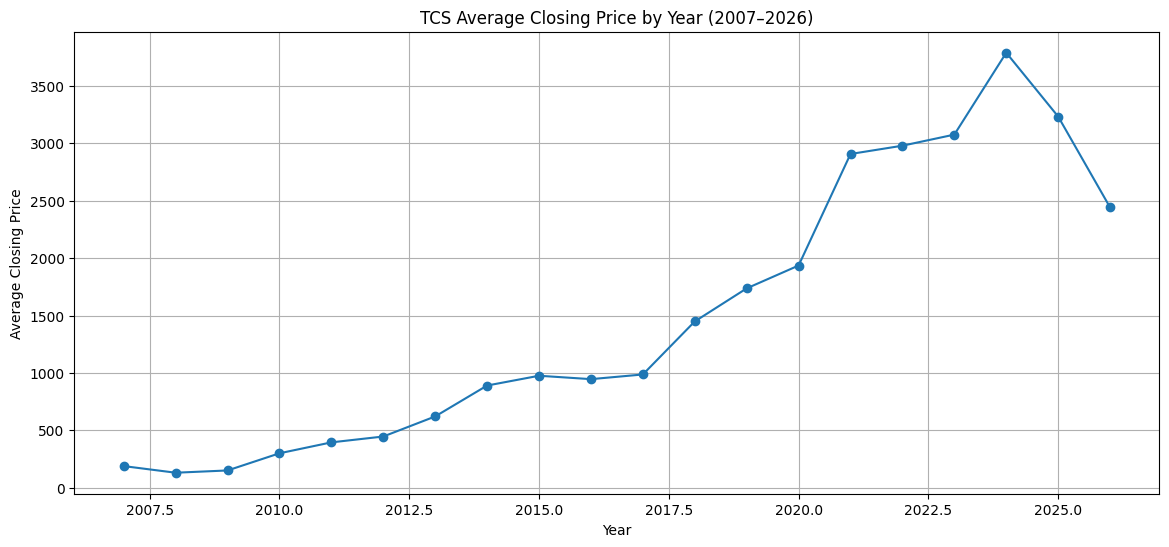

In [49]:
plt.figure(figsize=(14, 6))

plt.plot(
    yearly_summary["Year"],
    yearly_summary["Average_Close"],
    marker="o"
)

plt.title(
    "TCS Average Closing Price by Year (2007–2026)"
)

plt.xlabel("Year")
plt.ylabel("Average Closing Price")

plt.grid(True)

plt.show()

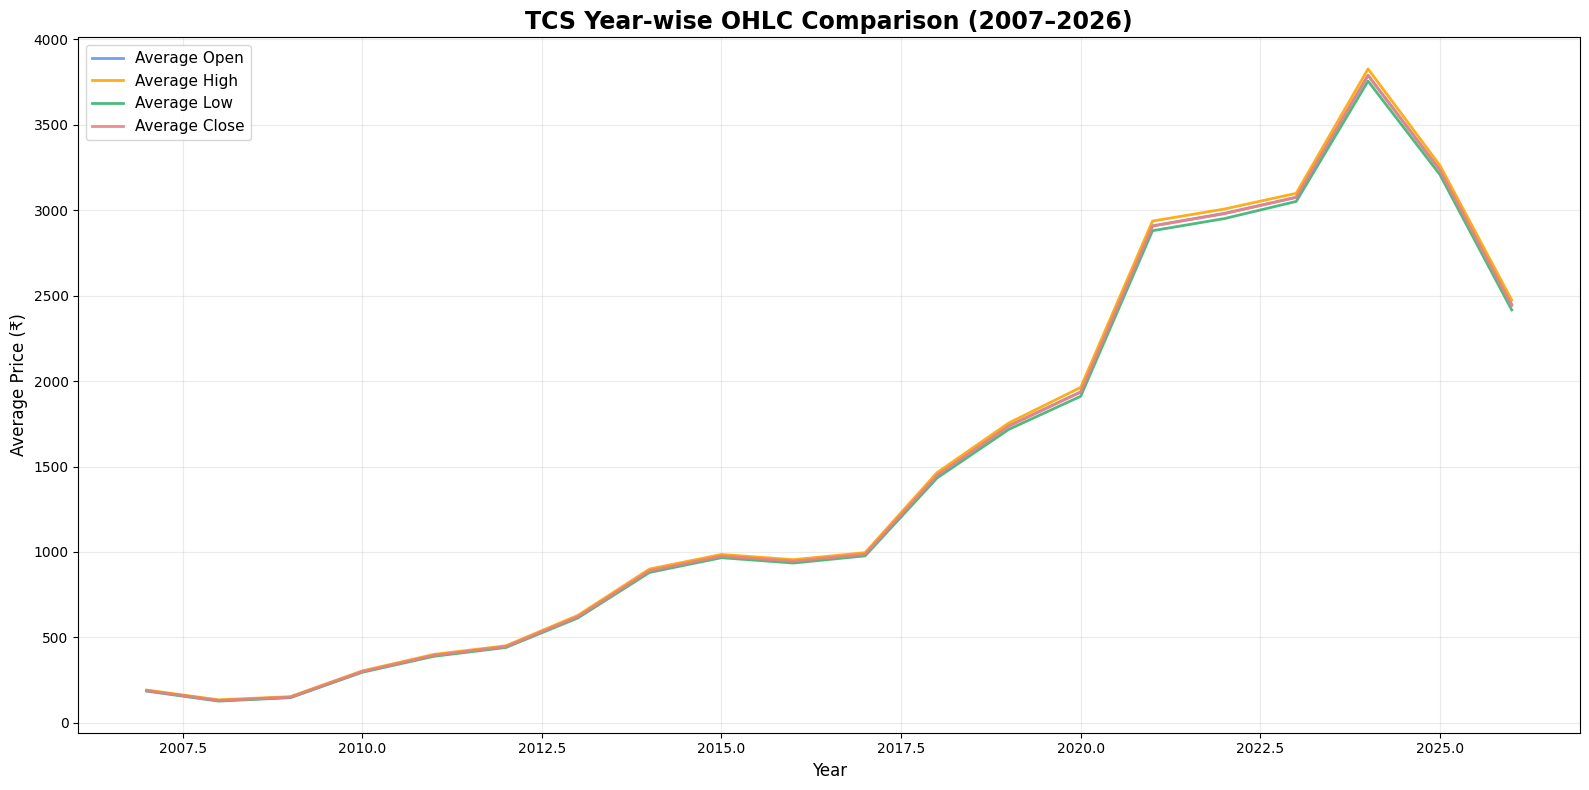

In [50]:
plt.figure(figsize=(16, 8))

plt.plot(
    yearly_summary["Year"],
    yearly_summary["Average_Open"],
    label="Average Open",
    color="cornflowerblue",
    linewidth=2,
    alpha=0.9
)

plt.plot(
    yearly_summary["Year"],
    yearly_summary["Average_High"],
    label="Average High",
    color="orange",
    linewidth=2,
    alpha=0.9
)

plt.plot(
    yearly_summary["Year"],
    yearly_summary["Average_Low"],
    label="Average Low",
    color="mediumseagreen",
    linewidth=2,
    alpha=0.9
)

plt.plot(
    yearly_summary["Year"],
    yearly_summary["Average_Close"],
    label="Average Close",
    color="lightcoral",
    linewidth=2,
    alpha=0.9
)

plt.title(
    "TCS Year-wise OHLC Comparison (2007–2026)",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Average Price (₹)", fontsize=12)

plt.legend(
    fontsize=11,
    loc="best"
)

plt.grid(
    True,
    alpha=0.25
)

plt.tight_layout()
plt.show()

In [51]:
yearly_summary.to_csv(
    "TCS_Yearly_OHLC_Comparison_2007_2026.csv",
    index=False
)

print("Yearly comparison saved successfully!")

Yearly comparison saved successfully!


In [52]:
# Day-to-day evaluation metrics from 2007–2026

daily_metrics = []

actual_values = []
predicted_values = []

for i in range(len(comparison)):

    actual_values.append(comparison["Actual_Close"].iloc[i])
    predicted_values.append(comparison["Predicted_Close"].iloc[i])

    actual_array = np.array(actual_values)
    predicted_array = np.array(predicted_values)

    # MAE
    daily_mae = mean_absolute_error(
        actual_array,
        predicted_array
    )

    # RMSE
    daily_rmse = np.sqrt(
        mean_squared_error(
            actual_array,
            predicted_array
        )
    )

    # R² needs at least 2 observations
    if len(actual_array) > 1:
        daily_r2 = r2_score(
            actual_array,
            predicted_array
        )
    else:
        daily_r2 = np.nan

    # -------------------------------------------------
    # Directional Accuracy
    # -------------------------------------------------
    if i > 0:

        previous_close = comparison["Actual_Close"].iloc[i - 1]

        actual_direction = np.sign(
            comparison["Actual_Close"].iloc[i] - previous_close
        )

        predicted_direction = np.sign(
            comparison["Predicted_Close"].iloc[i] - previous_close
        )

        directional_accuracy = (
            actual_direction == predicted_direction
        ) * 100

    else:
        directional_accuracy = np.nan

    # -------------------------------------------------
    # Prediction Accuracy
    # -------------------------------------------------
    actual_price = comparison["Actual_Close"].iloc[i]
    predicted_price = comparison["Predicted_Close"].iloc[i]

    percentage_error = (
        abs(actual_price - predicted_price)
        / abs(actual_price)
    ) * 100

    prediction_accuracy = 100 - percentage_error

    # -------------------------------------------------
    # Store metrics
    # -------------------------------------------------
    daily_metrics.append({
        "Date": comparison["Date"].iloc[i],
        "Actual_Close": actual_price,
        "Predicted_Close": predicted_price,
        "MAE": daily_mae,
        "RMSE": daily_rmse,
        "R²": daily_r2,
        "Directional Accuracy (%)": directional_accuracy,
        "Prediction Accuracy (%)": prediction_accuracy
    })


daily_metrics_df = pd.DataFrame(daily_metrics)

display(daily_metrics_df.head(20))

,Date,Actual_Close,Predicted_Close,MAE,RMSE,R²,Directional Accuracy (%),Prediction Accuracy (%)
0,2022-10-18 18:30:00,2785.883301,2754.960825,30.922476,30.922476,NaN,NaN,98.890030
1,2022-10-19 18:30:00,2768.324219,2786.420644,24.509450,25.334562,-7.326897,0.0,99.346304
2,2022-10-20 18:30:00,2789.765625,2768.506174,23.426117,24.053027,-5.648894,100.0,99.237948
3,2022-10-23 18:30:00,2790.118408,2790.172944,17.583222,20.830550,-4.440155,100.0,99.998045
4,2022-10-24 18:30:00,2785.970703,2790.324304,14.937298,18.732865,-4.418158,0.0,99.843731
5,2022-10-26 18:30:00,2791.133057,2786.048819,13.295121,17.226194,-3.863427,100.0,99.817843
6,2022-10-27 18:30:00,2817.515381,2792.000924,15.040740,18.637283,-0.927826,100.0,99.094434
7,2022-10-30 18:30:00,2876.237061,2817.089955,20.554036,27.225490,0.239405,0.0,97.943594
8,2022-10-31 18:30:00,2860.354736,2876.340332,20.046432,26.215681,0.436065,0.0,99.441132
9,2022-11-01 18:30:00,2829.516113,2860.175297,21.107707,26.693338,0.375747,100.0,98.916451


In [53]:
display(daily_metrics_df)

,Date,Actual_Close,Predicted_Close,MAE,RMSE,R²,Directional Accuracy (%),Prediction Accuracy (%)
0,2022-10-18 18:30:00,2785.883301,2754.960825,30.922476,30.922476,NaN,NaN,98.890030
1,2022-10-19 18:30:00,2768.324219,2786.420644,24.509450,25.334562,-7.326897,0.0,99.346304
2,2022-10-20 18:30:00,2789.765625,2768.506174,23.426117,24.053027,-5.648894,100.0,99.237948
3,2022-10-23 18:30:00,2790.118408,2790.172944,17.583222,20.830550,-4.440155,100.0,99.998045
4,2022-10-24 18:30:00,2785.970703,2790.324304,14.937298,18.732865,-4.418158,0.0,99.843731
...,...,...,...,...,...,...,...,...
969,2026-09-15 18:30:00,2190.000000,2190.227585,30.937802,43.415138,0.992820,100.0,99.989608
970,2026-09-16 18:30:00,2105.000000,2195.080189,30.998710,43.488963,0.992820,0.0,95.720656
971,2026-09-17 18:30:00,2128.699951,2106.578808,30.989577,43.472377,0.992849,100.0,98.960814
972,2026-09-20 18:30:00,2105.000000,2129.664495,30.983076,43.457226,0.992878,0.0,98.828290


In [55]:
# Save day-to-day evaluation metrics

output_file = "TCS_Daily_Evaluation_Metrics_2007_2026.csv"

daily_metrics_df.to_csv(
    output_file,
    index=False
)

print("File saved successfully!")
print("Filename:", output_file)
print("Total records:", len(daily_metrics_df))

File saved successfully!
Filename: TCS_Daily_Evaluation_Metrics_2007_2026.csv
Total records: 974


In [56]:
import pandas as pd
import matplotlib.pyplot as plt

daily_metrics_df["Date"] = pd.to_datetime(
    daily_metrics_df["Date"]
)

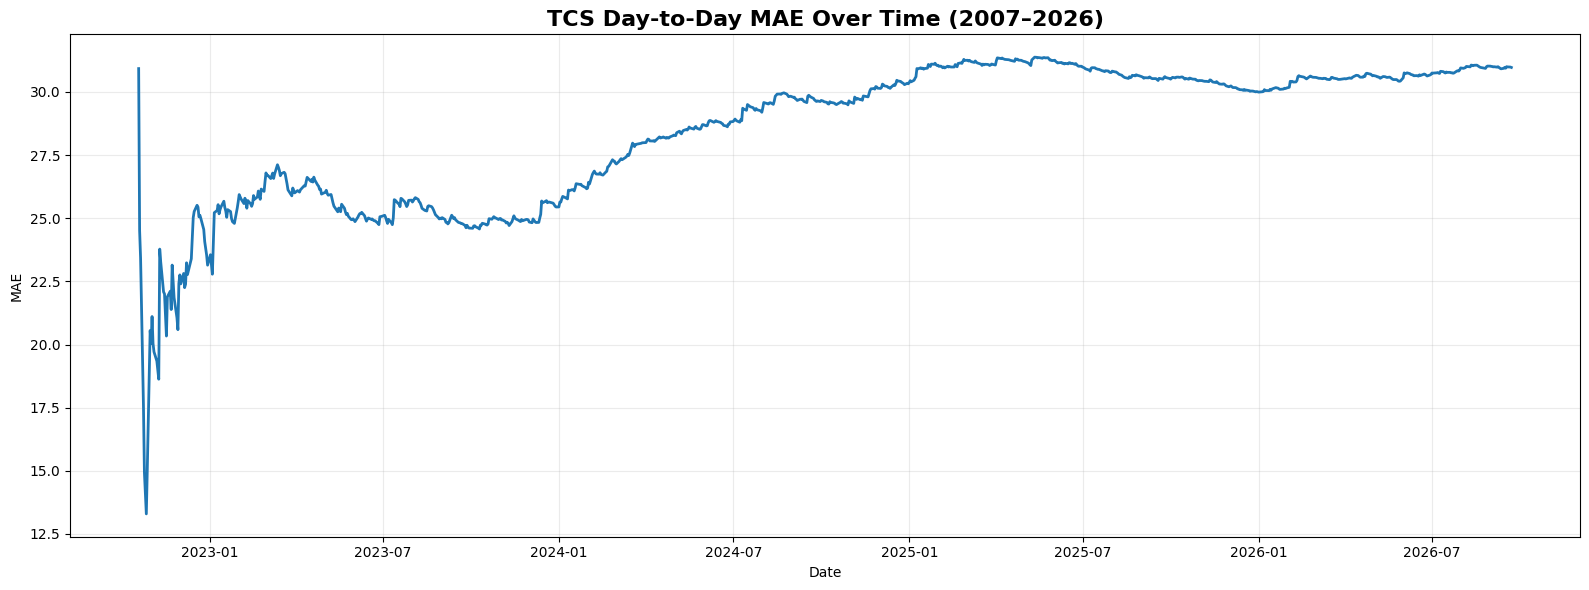

In [57]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_metrics_df["Date"],
    daily_metrics_df["MAE"],
    linewidth=2
)

plt.title(
    "TCS Day-to-Day MAE Over Time (2007–2026)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("MAE")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

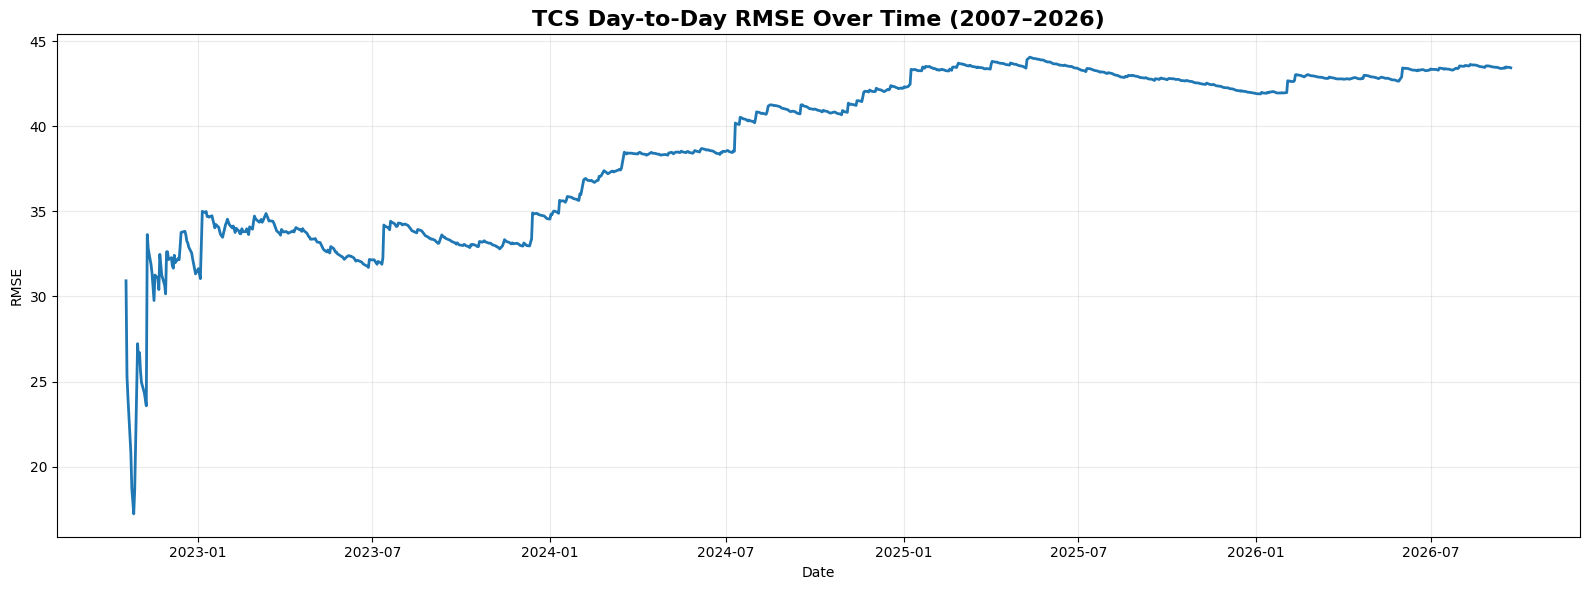

In [58]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_metrics_df["Date"],
    daily_metrics_df["RMSE"],
    linewidth=2
)

plt.title(
    "TCS Day-to-Day RMSE Over Time (2007–2026)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("RMSE")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

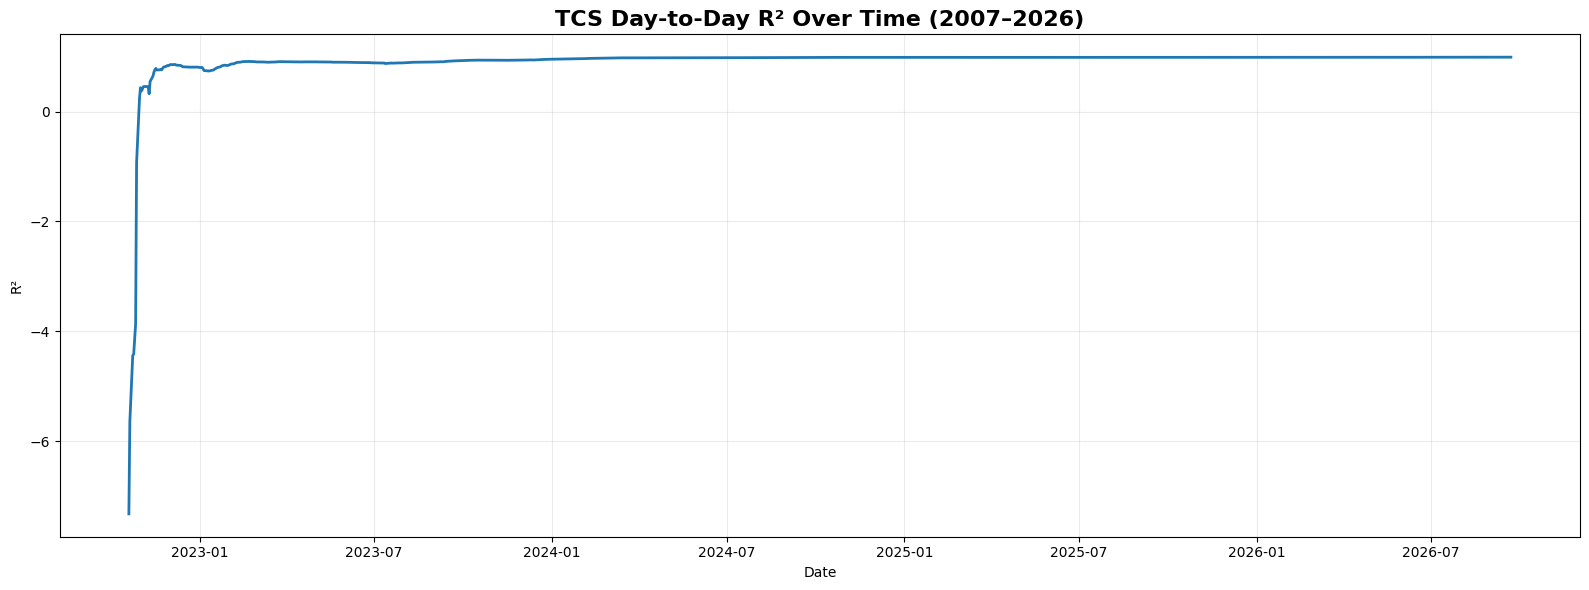

In [59]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_metrics_df["Date"],
    daily_metrics_df["R²"],
    linewidth=2
)

plt.title(
    "TCS Day-to-Day R² Over Time (2007–2026)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("R²")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

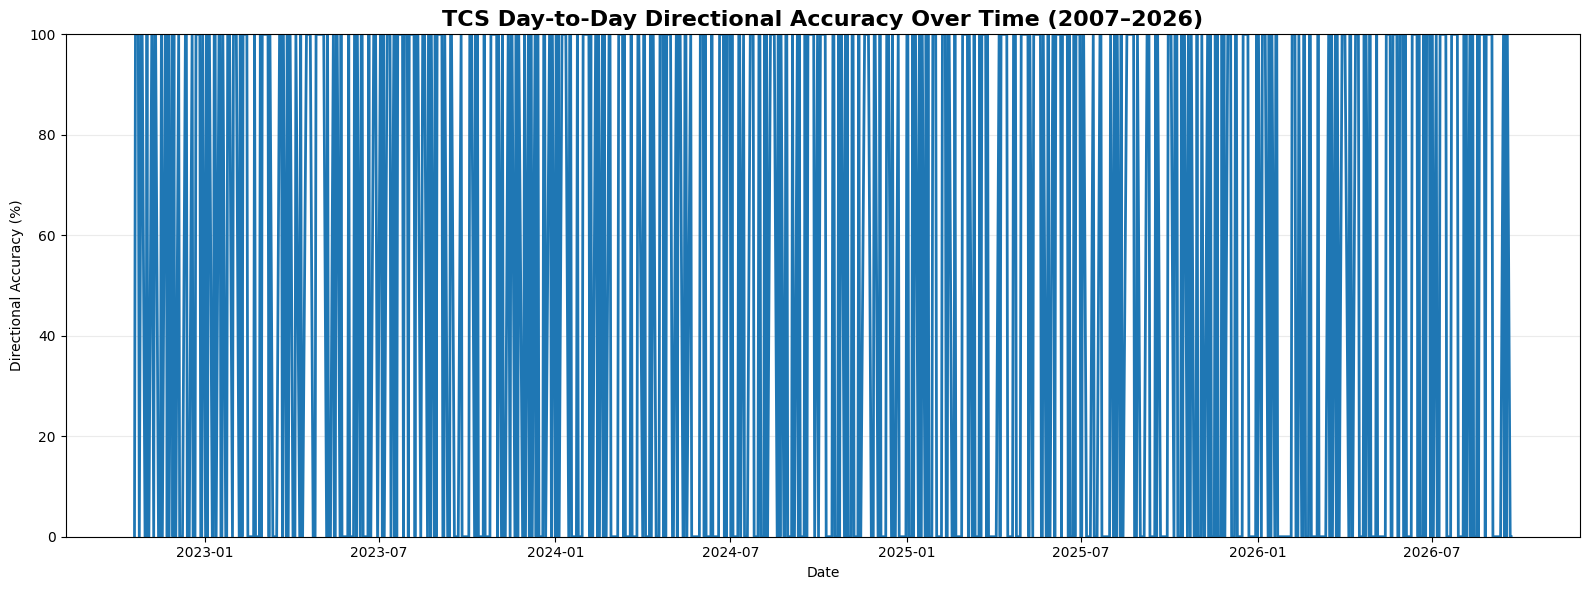

In [60]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_metrics_df["Date"],
    daily_metrics_df["Directional Accuracy (%)"],
    linewidth=2
)

plt.title(
    "TCS Day-to-Day Directional Accuracy Over Time (2007–2026)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Directional Accuracy (%)")
plt.ylim(0, 100)
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

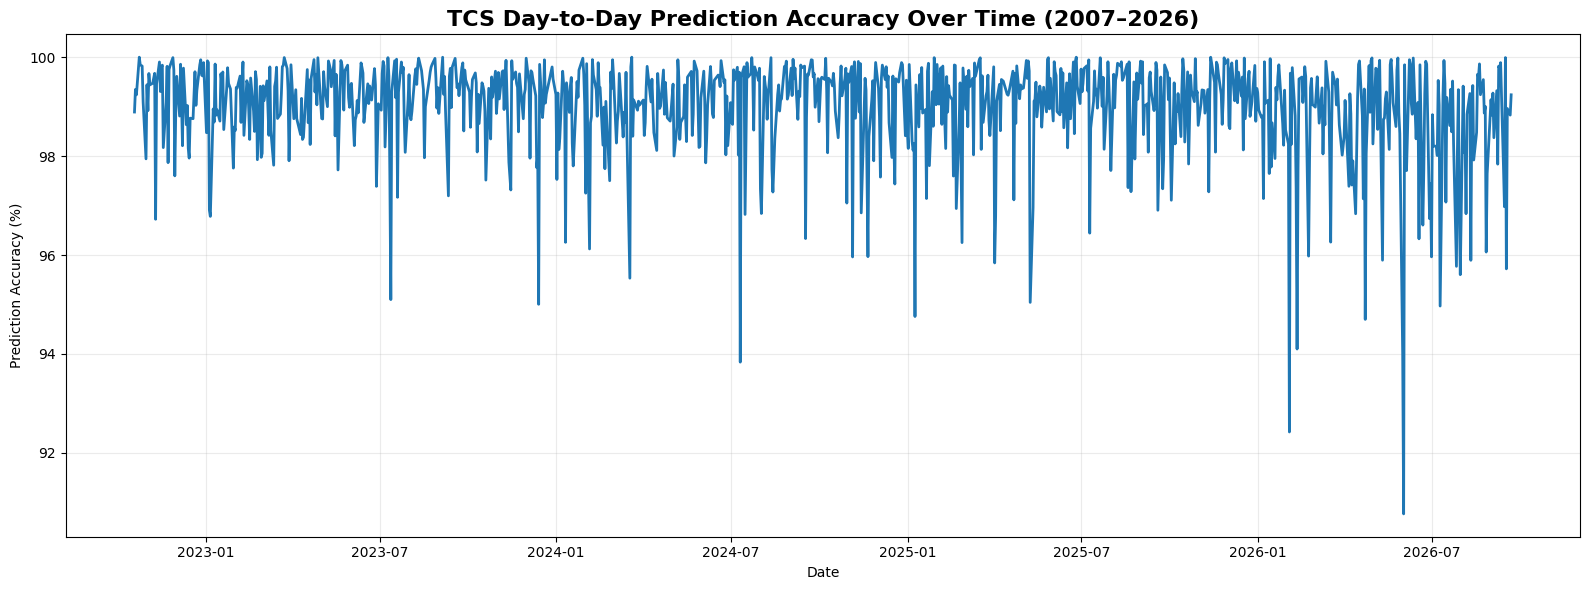

In [61]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_metrics_df["Date"],
    daily_metrics_df["Prediction Accuracy (%)"],
    linewidth=2
)

plt.title(
    "TCS Day-to-Day Prediction Accuracy Over Time (2007–2026)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Prediction Accuracy (%)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [62]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Make sure data is sorted chronologically
comparison = comparison.sort_values("Date").reset_index(drop=True)

# Convert Date
comparison["Date"] = pd.to_datetime(comparison["Date"])

# Rolling window
window = 30

rolling_metrics = []

for i in range(len(comparison)):

    # Not enough observations for a 30-day window
    if i < window - 1:
        rolling_metrics.append({
            "Date": comparison["Date"].iloc[i],
            "MAE": np.nan,
            "RMSE": np.nan,
            "R²": np.nan,
            "Directional Accuracy (%)": np.nan,
            "Prediction Accuracy (%)": np.nan
        })
        continue

    # Get last 30 trading days
    window_data = comparison.iloc[i-window+1:i+1]

    actual = window_data["Actual_Close"].values
    predicted = window_data["Predicted_Close"].values

    # -------------------------
    # MAE
    # -------------------------
    mae = mean_absolute_error(
        actual,
        predicted
    )

    # -------------------------
    # RMSE
    # -------------------------
    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    # -------------------------
    # R²
    # -------------------------
    if len(np.unique(actual)) > 1:
        r2 = r2_score(
            actual,
            predicted
        )
    else:
        r2 = np.nan

    # -------------------------
    # Directional Accuracy
    # -------------------------
    actual_direction = []
    predicted_direction = []

    for j in range(1, len(window_data)):

        previous_close = window_data["Actual_Close"].iloc[j-1]

        actual_change = (
            window_data["Actual_Close"].iloc[j]
            - previous_close
        )

        predicted_change = (
            window_data["Predicted_Close"].iloc[j]
            - previous_close
        )

        actual_direction.append(
            np.sign(actual_change)
        )

        predicted_direction.append(
            np.sign(predicted_change)
        )

    directional_accuracy = (
        np.mean(
            np.array(actual_direction)
            ==
            np.array(predicted_direction)
        )
        * 100
    )

    # -------------------------
    # Prediction Accuracy
    # -------------------------
    percentage_error = (
        np.abs(actual - predicted)
        / np.abs(actual)
    ) * 100

    prediction_accuracy = (
        100 - np.mean(percentage_error)
    )

    # -------------------------
    # Store results
    # -------------------------
    rolling_metrics.append({
        "Date": comparison["Date"].iloc[i],
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2,
        "Directional Accuracy (%)": directional_accuracy,
        "Prediction Accuracy (%)": prediction_accuracy
    })


# Create DataFrame
daily_metrics_df = pd.DataFrame(
    rolling_metrics
)

# Remove initial NaN rows
daily_metrics_df = daily_metrics_df.dropna().reset_index(drop=True)

# Display results
display(
    daily_metrics_df.head(10)
)

,Date,MAE,RMSE,R²,Directional Accuracy (%),Prediction Accuracy (%)
0,2022-11-30 18:30:00,22.755098,32.630001,0.848368,48.275862,99.219031
1,2022-12-01 18:30:00,22.116085,32.209430,0.853164,48.275862,99.243071
2,2022-12-04 18:30:00,22.699088,32.691661,0.838212,48.275862,99.225150
3,2022-12-05 18:30:00,22.133958,32.469942,0.830575,44.827586,99.245740
4,2022-12-06 18:30:00,23.027848,32.838481,0.810202,44.827586,99.215508
5,2022-12-07 18:30:00,24.617256,34.175893,0.768049,41.379310,99.161017
6,2022-12-08 18:30:00,24.663808,34.183769,0.735530,37.931034,99.159639
7,2022-12-11 18:30:00,25.152954,34.650664,0.697052,41.379310,99.144261
8,2022-12-12 18:30:00,24.149831,33.349551,0.712504,44.827586,99.180194
9,2022-12-13 18:30:00,25.406736,34.637719,0.673413,41.379310,99.137452


In [63]:
output_file = "TCS_Rolling_30Day_Evaluation_Metrics_2007_2026.csv"

daily_metrics_df.to_csv(
    output_file,
    index=False
)

print("Saved successfully!")
print("File:", output_file)
print("Records:", len(daily_metrics_df))

Saved successfully!
File: TCS_Rolling_30Day_Evaluation_Metrics_2007_2026.csv
Records: 945


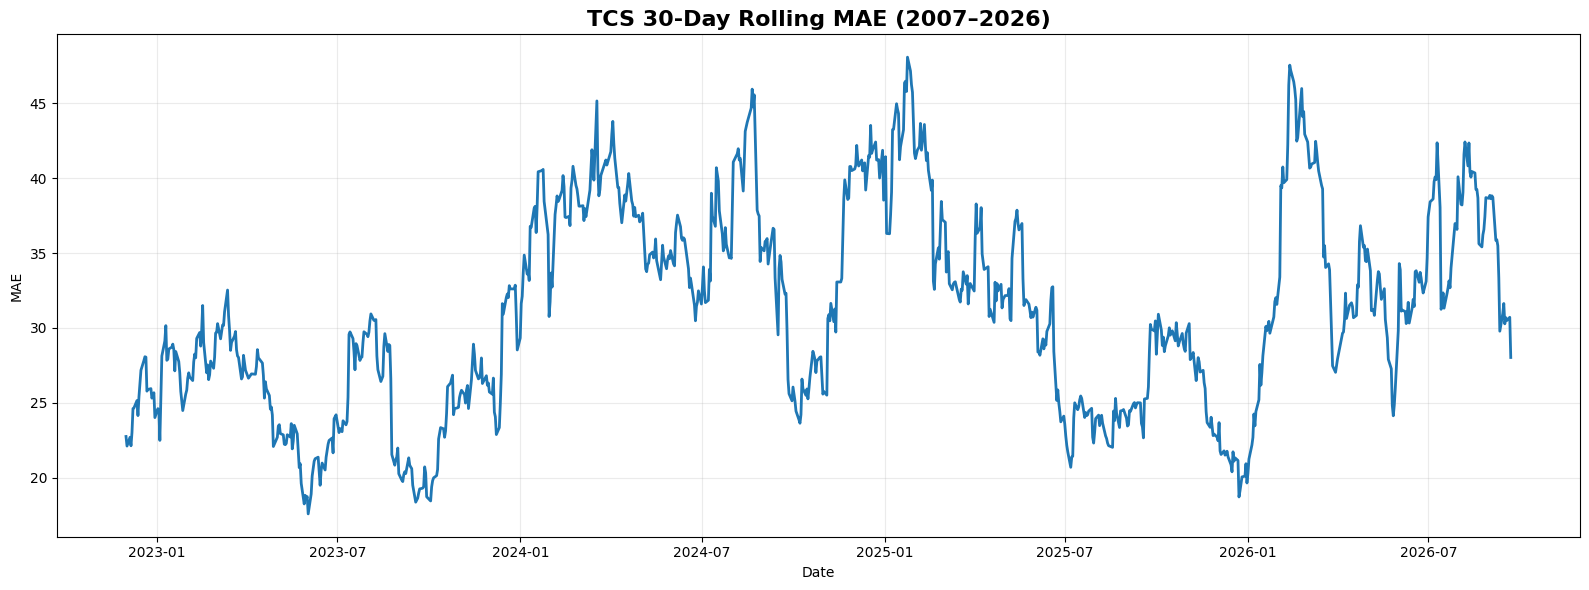

In [64]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_metrics_df["Date"],
    daily_metrics_df["MAE"],
    linewidth=2
)

plt.title(
    "TCS 30-Day Rolling MAE (2007–2026)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("MAE")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

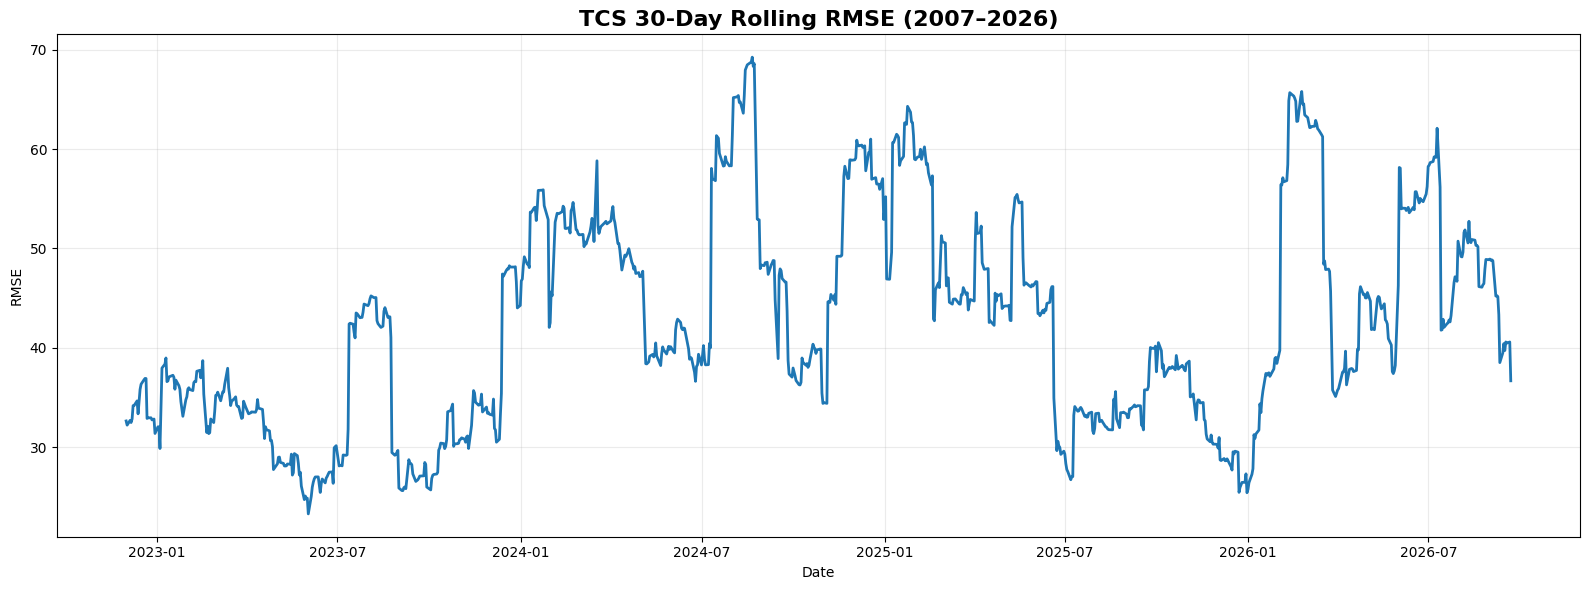

In [65]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_metrics_df["Date"],
    daily_metrics_df["RMSE"],
    linewidth=2
)

plt.title(
    "TCS 30-Day Rolling RMSE (2007–2026)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("RMSE")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

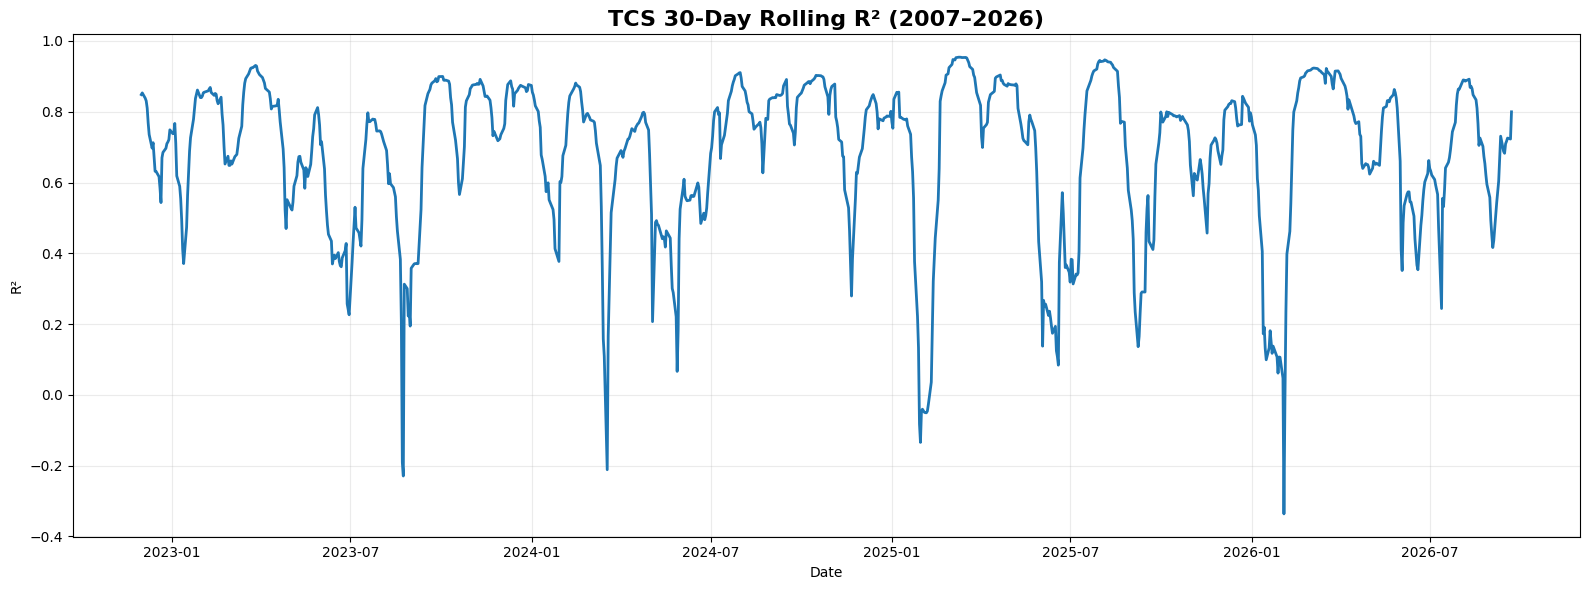

In [66]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_metrics_df["Date"],
    daily_metrics_df["R²"],
    linewidth=2
)

plt.title(
    "TCS 30-Day Rolling R² (2007–2026)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("R²")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

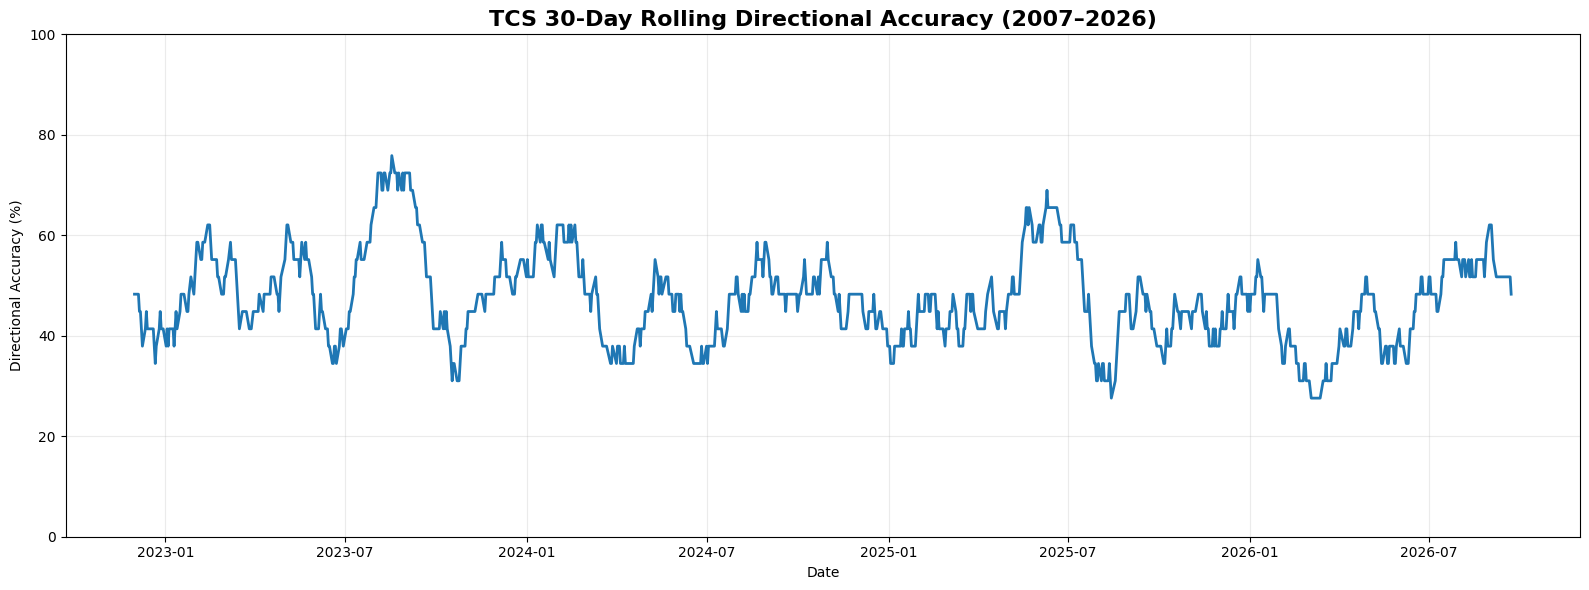

In [67]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_metrics_df["Date"],
    daily_metrics_df["Directional Accuracy (%)"],
    linewidth=2
)

plt.title(
    "TCS 30-Day Rolling Directional Accuracy (2007–2026)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Directional Accuracy (%)")
plt.ylim(0, 100)
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

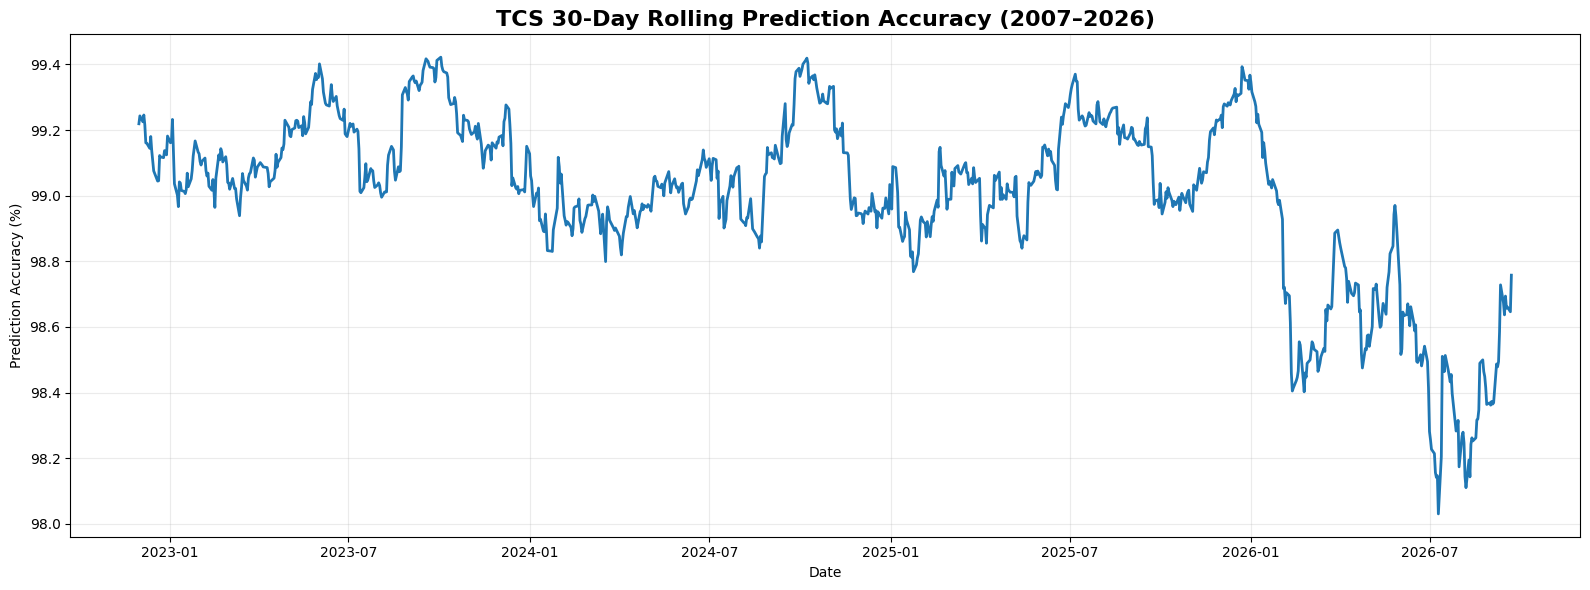

In [68]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_metrics_df["Date"],
    daily_metrics_df["Prediction Accuracy (%)"],
    linewidth=2
)

plt.title(
    "TCS 30-Day Rolling Prediction Accuracy (2007–2026)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Prediction Accuracy (%)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [69]:
import pandas as pd
import numpy as np

# --------------------------------------------------
# Dates you want to predict from
# --------------------------------------------------

prediction_dates = [
    "2026-09-25",
    "2026-09-28",
    "2026-09-29",
    "2026-09-30",
    "2026-10-01"
]

# --------------------------------------------------
# Actual OHLCV data from Yahoo Finance
# --------------------------------------------------

new_data = pd.DataFrame({
    "Date": pd.to_datetime(prediction_dates),

    "Open": [
        2054.00,
        2100.00,
        2065.00,
        2069.00,
        2052.60
    ],

    "High": [
        2090.20,
        2100.00,
        2085.10,
        2101.00,
        2093.90
    ],

    "Low": [
        2038.10,
        2051.00,
        2032.40,
        2050.60,
        2045.10
    ],

    "Close": [
        2082.00,
        2070.70,
        2032.40,
        2050.60,
        2075.00
    ],

    "Volume": [
        3342195,
        2460000,
        4440000,
        3656425,
        3428501
    ]
})

# --------------------------------------------------
# Features used by your Linear Regression model
# --------------------------------------------------

features = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume"
]

X_new = new_data[features]

# --------------------------------------------------
# Predict next closing price
# --------------------------------------------------

predicted_prices = model.predict(X_new)

new_data["Predicted_Next_Close"] = predicted_prices

# --------------------------------------------------
# Display result
# --------------------------------------------------

result = new_data[
    [
        "Date",
        "Close",
        "Predicted_Next_Close"
    ]
].copy()

result["Date"] = result["Date"].dt.strftime("%d/%m/%Y")

result.rename(
    columns={
        "Close": "Actual_Close",
        "Predicted_Next_Close": "Predicted_Next_Day_Close"
    },
    inplace=True
)

display(result)

,Date,Actual_Close,Predicted_Next_Day_Close
0,25/09/2026,2082.0,2082.290394
1,28/09/2026,2070.7,2070.658464
2,29/09/2026,2032.4,2034.679766
3,30/09/2026,2050.6,2053.398960
4,01/10/2026,2075.0,2076.346058


In [5]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# Actual and predicted prices
# --------------------------------------------------

actual = np.array([
    2082.00,
    2070.70,
    2032.40,
    2050.60,
    2075.00
])

predicted = np.array([
    2082.290394,
    2070.658464,
    2034.679766,
    2053.398960,
    2076.346058
])

# --------------------------------------------------
# 1. MAE
# --------------------------------------------------

mae = mean_absolute_error(actual, predicted)

# --------------------------------------------------
# 2. RMSE
# --------------------------------------------------

rmse = np.sqrt(mean_squared_error(actual, predicted))

# --------------------------------------------------
# 3. R²
# --------------------------------------------------

r2 = r2_score(actual, predicted)

# --------------------------------------------------
# 4. Directional Accuracy
# --------------------------------------------------

actual_direction = np.sign(np.diff(actual))
predicted_direction = np.sign(np.diff(predicted))

directional_accuracy = (
    np.mean(actual_direction == predicted_direction) * 100
)

# --------------------------------------------------
# 5. Prediction Accuracy / Price Proximity
# --------------------------------------------------

percentage_error = (
    np.abs(actual - predicted) / np.abs(actual)
) * 100

prediction_accuracy = 100 - np.mean(percentage_error)

# --------------------------------------------------
# Display results
# --------------------------------------------------

print("Evaluation of 5 Next-Day Predictions")
print("--------------------------------------")
print(f"MAE                  : {mae:.4f}")
print(f"RMSE                 : {rmse:.4f}")
print(f"R²                   : {r2:.4f}")
print(f"Directional Accuracy : {directional_accuracy:.2f}%")
print(f"Prediction Accuracy  : {prediction_accuracy:.2f}%")

Evaluation of 5 Next-Day Predictions
--------------------------------------
MAE                  : 1.3513
RMSE                 : 1.7280
R²                   : 0.9910
Directional Accuracy : 100.00%
Prediction Accuracy  : 99.93%


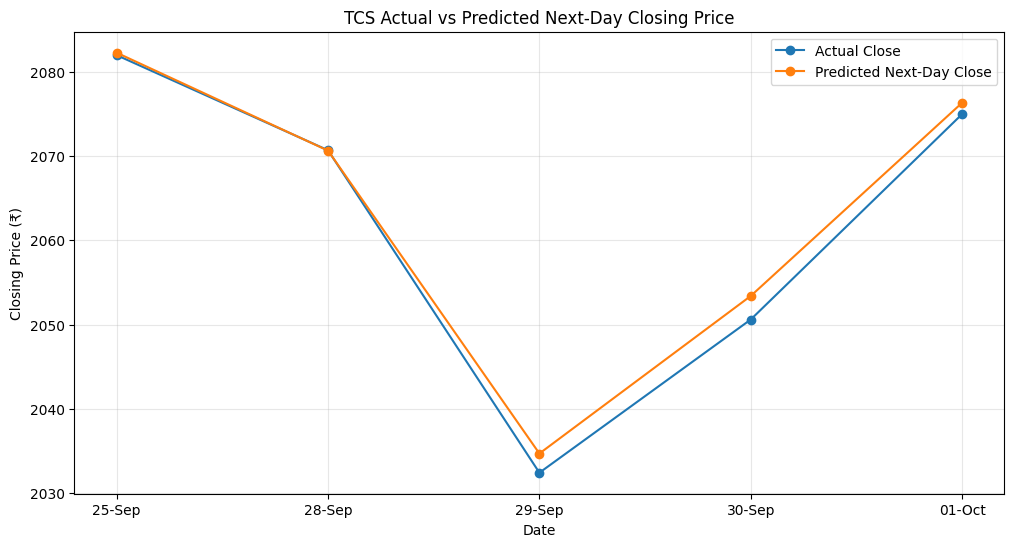

In [6]:
import matplotlib.pyplot as plt

dates = [
    "25-Sep",
    "28-Sep",
    "29-Sep",
    "30-Sep",
    "01-Oct"
]

plt.figure(figsize=(12, 6))

plt.plot(
    dates,
    actual,
    marker="o",
    label="Actual Close"
)

plt.plot(
    dates,
    predicted,
    marker="o",
    label="Predicted Next-Day Close"
)

plt.title("TCS Actual vs Predicted Next-Day Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (₹)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# -----------------------------
# Training metrics
# -----------------------------

train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

# -----------------------------
# Testing metrics
# -----------------------------

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

# -----------------------------
# Display results
# -----------------------------

print("TRAINING SET")
print("MAE  :", round(train_mae, 4))
print("RMSE :", round(train_rmse, 4))
print("R²   :", round(train_r2, 4))

print("\nTESTING SET")
print("MAE  :", round(test_mae, 4))
print("RMSE :", round(test_rmse, 4))
print("R²   :", round(test_r2, 4))

NameError: name 'X_train' is not defined

In [73]:
mae_gap = test_mae - train_mae
rmse_gap = test_rmse - train_rmse
r2_gap = train_r2 - test_r2

print("Training–Testing Gaps")
print("---------------------")
print(f"MAE Gap  : {mae_gap:.4f}")
print(f"RMSE Gap : {rmse_gap:.4f}")
print(f"R² Gap   : {r2_gap:.4f}")

Training–Testing Gaps
---------------------
MAE Gap  : 18.9110
RMSE Gap : 22.5061
R² Gap   : 0.0065


In [2]:
import pandas as pd

# Load TCS historical data
data = pd.read_csv("TCS_LinearRegression_Data_2007_2026.csv")

# Convert Date column
data["Date"] = pd.to_datetime(data["Date"])

# Sort chronologically
data = data.sort_values("Date").reset_index(drop=True)

# Create next-day closing price as target
data["Target_Close"] = data["Close"].shift(-1)

# Features: today's OHLCV
features = ["Open", "High", "Low", "Close", "Volume"]

X = data[features]
y = data["Target_Close"]

# Remove last row because it has no next-day target
X = X.iloc[:-1]
y = y.iloc[:-1]

print("Dataset shape:", data.shape)
print("Features:", features)
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFirst 5 feature rows:")
display(X.head())

print("\nFirst 5 target values:")
display(y.head())

Dataset shape: (4869, 7)
Features: ['Open', 'High', 'Low', 'Close', 'Volume']
X shape: (4868, 5)
y shape: (4868,)

First 5 feature rows:


,Open,High,Low,Close,Volume
0,200.694102,205.362921,198.506607,203.812088,1545060
1,204.546655,210.260248,202.285708,208.978775,4384972
2,209.770500,209.770500,204.073227,205.534286,3970700
3,206.505629,207.093309,204.563003,206.179138,2718740
4,205.526108,205.526108,198.343306,203.044785,4951892



First 5 target values:


0    208.978775
1    205.534286
2    206.179138
3    203.044785
4    205.101685
Name: Target_Close, dtype: float64

In [3]:
# Chronological 80:20 split

split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining period:")
print(data["Date"].iloc[0], "to", data["Date"].iloc[split_index - 1])

print("\nTesting period:")
print(data["Date"].iloc[split_index], "to", data["Date"].iloc[-2])

Training data:
X_train: (3894, 5)
y_train: (3894,)

Testing data:
X_test: (974, 5)
y_test: (974,)

Training period:
2007-01-02 00:00:00+05:30 to 2022-10-17 00:00:00+05:30

Testing period:
2022-10-18 00:00:00+05:30 to 2026-09-21 00:00:00+05:30


In [4]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

print("\nFirst 5 scaled training rows:")
print(X_train_scaled[:5])

X_train_scaled shape: (3894, 5)
X_test_scaled shape: (974, 5)

First 5 scaled training rows:
[[-0.95977118 -0.95847684 -0.95833642 -0.95630027 -0.62459547]
 [-0.95538141 -0.95294645 -0.95398616 -0.95040853  0.37628396]
 [-0.94942912 -0.9534995  -0.95192848 -0.95433639  0.23028073]
 [-0.95314926 -0.95652277 -0.95136468 -0.95360105 -0.21095161]
 [-0.95426537 -0.95829256 -0.95852441 -0.95717526  0.57608542]]


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ==========================================
# 1. TRAIN LINEAR REGRESSION
# ==========================================

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

# ==========================================
# 2. NAIVE BASELINE PREDICTION
# Tomorrow's Close = Today's Close
# ==========================================

naive_predictions = X_test["Close"].to_numpy()

# ==========================================
# 3. CALCULATE METRICS
# ==========================================

def calculate_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

linear_metrics = calculate_metrics(
    y_test, linear_predictions
)

naive_metrics = calculate_metrics(
    y_test, naive_predictions
)

comparison = pd.DataFrame(
    [linear_metrics, naive_metrics],
    index=["Linear Regression", "Naive Baseline"]
)

print("MODEL PERFORMANCE COMPARISON")
print("=" * 55)
print(comparison.round(4))

# ==========================================
# 4. COMPARE METRICS WITH BAR GRAPHS
# ==========================================

metrics = ["MAE", "RMSE", "R2"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metric in zip(axes, metrics):
    comparison[metric].plot(
        kind="bar", ax=ax, rot=15
    )
    ax.set_title(f"{metric} Comparison")
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# 5. ACTUAL VS PREDICTED PRICES
# ==========================================

plt.figure(figsize=(14, 6))

plt.plot(
    np.asarray(y_test),
    label="Actual Close",
    linewidth=2
)

plt.plot(
    linear_predictions,
    label="Linear Regression",
    alpha=0.8
)

plt.plot(
    naive_predictions,
    label="Naive Baseline",
    alpha=0.8
)

plt.title("TCS: Actual vs Predicted Closing Prices")
plt.xlabel("Test Observation")
plt.ylabel("Closing Price (₹)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 6. SAVE RESULTS
# ==========================================

comparison.to_csv(
    "TCS_Linear_vs_Naive_Comparison.csv"
)

predictions_df = pd.DataFrame({
    "Actual_Next_Day_Close": np.asarray(y_test),
    "Linear_Regression_Prediction": linear_predictions,
    "Naive_Baseline_Prediction": naive_predictions
})

predictions_df.to_csv(
    "TCS_Linear_vs_Naive_Predictions.csv",
    index=False
)

print("\nFiles saved:")
print("TCS_Linear_vs_Naive_Comparison.csv")
print("TCS_Linear_vs_Naive_Predictions.csv")


NameError: name 'X_train' is not defined